In [1]:
%pip -q install tif1 pandas numpy scipy seaborn matplotlib pyarrow requests

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 1.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 133.0/133.0 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.4/62.4 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 45.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 72.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 13.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 229.1/229.1 kB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 876.6/876.6 kB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.5/54.5 MB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 488

In [3]:
from pathlib import Path
import os, subprocess, shutil, json, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

YEAR=2025
EVENTS=['Austrian Grand Prix','Azerbaijan Grand Prix']
USE_DRIVE=True       # False = zwykły Jupyter na komputerze
DOWNLOAD_RAW=True    # False gdy kopia RAW już istnieje
FETCH_TELEMETRY=False # po audycie zmień na True
MAX_TELEMETRY_LAPS_PER_GP=10 # None = próbuj pobrać wszystkie (powolne)

if USE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    ROOT=Path('/content/drive/MyDrive/F1-Research')
else:
    ROOT=Path.cwd()/'F1-Research'
RAW=ROOT/'raw'/str(YEAR)
PROCESSED=ROOT/'processed'
REPORTS=ROOT/'reports'
for p in (RAW, PROCESSED, REPORTS): p.mkdir(parents=True,exist_ok=True)
print('Folder projektu:', ROOT)

Mounted at /content/drive
Folder projektu: /content/drive/MyDrive/F1-Research


Pobieranie RAW danych

In [4]:
REPO='https://github.com/TracingInsights-Archive/2025.git'
TEMP=Path('/content/f1-source') if USE_DRIVE else ROOT/'_repo_temp'
if DOWNLOAD_RAW:
    if TEMP.exists(): shutil.rmtree(TEMP)
    subprocess.run(['git','clone','--depth','1','--filter=blob:none','--sparse',REPO,str(TEMP)],check=True)
    paths=[f'{ev}/Race' for ev in EVENTS]
    subprocess.run(['git','-C',str(TEMP),'sparse-checkout','set','--',*paths],check=True)
    commit=subprocess.check_output(['git','-C',str(TEMP),'rev-parse','HEAD'],text=True).strip()
    for ev in EVENTS:
        src=TEMP/ev/'Race'; dst=RAW/ev/'Race'
        if not src.is_dir(): raise RuntimeError(f'Nie znaleziono {src}. Sprawdź nazwy katalogów w repozytorium.')
        if dst.exists(): shutil.rmtree(dst)
        shutil.copytree(src,dst)
    (ROOT/'source_manifest.json').write_text(json.dumps({'repository':REPO,'commit':commit,'year':YEAR,'events':EVENTS,'session':'Race'},indent=2),encoding='utf8')
    print('Źródłowy commit:', commit)
else:
    print('Używam już pobranych plików RAW')
assert all((RAW/ev/'Race').is_dir() for ev in EVENTS), 'Brak danych Race: uruchom pobieranie.'

Źródłowy commit: f7a5324cae589ecdbfbf15a114b784dec180b1f6


In [5]:
inventory=[]
for ev in EVENTS:
    folder=RAW/ev/'Race'
    files=list(folder.rglob('*.json'))
    kinds={}
    for f in files:
        name='telemetry' if f.name.endswith('_tel.json') else f.name
        kinds[name]=kinds.get(name,0)+1
    inventory.append({'event':ev,'json_files':len(files),'size_mb':round(sum(f.stat().st_size for f in files)/1024**2,2),'kinds':str(kinds)})
inv=pd.DataFrame(inventory)
display(inv)
inv.to_csv(REPORTS/'file_inventory.csv',index=False)
for ev in EVENTS:
    files=list((RAW/ev/'Race').rglob('*.json'))
    print('\n',ev,'— przykładowe ścieżki:')
    for f in files[:12]: print(f.relative_to(RAW))
    representatives={}
    for f in files:
        kind='telemetry' if f.name.endswith('_tel.json') else f.name
        if kind not in representatives: representatives[kind]=f
    for kind,f in representatives.items():
        try:
            x=json.loads(f.read_text(encoding='utf8'))
            print(kind, 'root:',type(x).__name__,'keys:',list(x)[:35] if isinstance(x,dict) else '<lista>')
            if isinstance(x,dict) and kind=='telemetry':
                print('  telemetry sections:', {k:list(v)[:20] for k,v in x.items() if isinstance(v,dict)})
        except Exception as e: print('Błąd JSON:',f,e)

,event,json_files,size_mb,kinds
0,Austrian Grand Prix,1151,117.62,"{'corners.json': 1, 'rcm.json': 1, 'drivers.js..."
1,Azerbaijan Grand Prix,992,153.64,"{'corners.json': 1, 'rcm.json': 1, 'drivers.js..."



 Austrian Grand Prix — przykładowe ścieżki:
Austrian Grand Prix/Race/corners.json
Austrian Grand Prix/Race/rcm.json
Austrian Grand Prix/Race/drivers.json
Austrian Grand Prix/Race/weather.json
Austrian Grand Prix/Race/ANT/laptimes.json
Austrian Grand Prix/Race/ANT/1_tel.json
Austrian Grand Prix/Race/BOR/27_tel.json
Austrian Grand Prix/Race/BOR/43_tel.json
Austrian Grand Prix/Race/BOR/6_tel.json
Austrian Grand Prix/Race/BOR/9_tel.json
Austrian Grand Prix/Race/BOR/24_tel.json
Austrian Grand Prix/Race/BOR/21_tel.json
corners.json root: dict keys: ['CornerNumber', 'X', 'Y', 'Angle', 'Distance', 'Rotation']
rcm.json root: dict keys: ['time', 'cat', 'msg', 'status', 'flag', 'scope', 'sector', 'dNum', 'lap']
drivers.json root: dict keys: ['drivers']
weather.json root: dict keys: ['wT', 'wAT', 'wH', 'wP', 'wR', 'wTT', 'wWD', 'wWS']
laptimes.json root: dict keys: ['time', 'lap', 'compound', 'stint', 's1', 's2', 's3', 'ms1', 'ms2', 'ms3', 'life', 'pos', 'status', 'pb', 'sesT', 'drv', 'dNum', 'po

In [6]:
import tif1
frames=[]; sessions={}
for ev in EVENTS:
    s=tif1.get_session(YEAR,ev,'Race')
    sessions[ev]=s
    x=pd.DataFrame(s.laps).copy()
    if x.empty: raise RuntimeError(f'Brak okrążeń dla {ev}')
    x['Event']=ev; x['Year']=YEAR; x['Session']='Race'
    frames.append(x)
    print(ev,':',len(x),'okrążeń; liczba kolumn:',len(x.columns))
laps=pd.concat(frames,ignore_index=True,sort=False)
for c in laps.select_dtypes(include=['timedelta64[ns]']).columns:
    laps[c+'Seconds']=laps[c].dt.total_seconds()
# Konwersja do formatu zapisu Parquet: timedelta wspierany, ale złożone obiekty nie zawsze.
for c in laps.columns:
    if laps[c].dtype=='object' and laps[c].dropna().map(lambda v:isinstance(v,(dict,list,tuple))).any():
        laps[c]=laps[c].map(lambda v: json.dumps(v,default=str) if isinstance(v,(dict,list,tuple)) else v)
laps.to_parquet(PROCESSED/'race_laps_2025.parquet',index=False)
display(laps.head(3))
print('Kolumny:',list(laps.columns))

Austrian Grand Prix : 1127 okrążeń; liczba kolumn: 49
Azerbaijan Grand Prix : 968 okrążeń; liczba kolumn: 49


,index,Time,Driver,DriverNumber,LapTime,LapNumber,Stint,PitOutTime,PitInTime,Sector1Time,...,PitOutTimeSeconds,PitInTimeSeconds,Sector1TimeSeconds,Sector2TimeSeconds,Sector3TimeSeconds,Sector1SessionTimeSeconds,Sector2SessionTimeSeconds,Sector3SessionTimeSeconds,LapStartTimeSeconds,WeatherTimeSeconds
0,0,0 days 01:12:37.412000,NOR,4,0 days 00:01:28.861000,1.0,1.0,NaT,NaT,NaT,...,NaN,NaN,NaN,31.326,36.909,NaN,4320.537,4357.527,4268.287,4288.860
1,1,0 days 01:14:31.838000,NOR,4,0 days 00:01:54.426000,2.0,1.0,NaT,NaT,0 days 00:00:26.438000,...,NaN,NaN,26.438,53.661,34.327,4383.884,4437.545,4471.872,4357.412,4408.877
2,2,0 days 01:16:24.860000,NOR,4,0 days 00:01:53.022000,3.0,1.0,NaT,NaT,0 days 00:00:26.434000,...,NaN,NaN,26.434,50.148,36.440,4498.306,4548.454,4584.894,4471.838,4528.888


Kolumny: ['index', 'Time', 'Driver', 'DriverNumber', 'LapTime', 'LapNumber', 'Stint', 'PitOutTime', 'PitInTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'IsPersonalBest', 'Compound', 'TyreLife', 'FreshTyre', 'Team', 'LapStartTime', 'LapStartDate', 'TrackStatus', 'Position', 'Deleted', 'DeletedReason', 'FastF1Generated', 'IsAccurate', 'WeatherTime', 'AirTemp', 'Humidity', 'Pressure', 'Rainfall', 'TrackTemp', 'WindDirection', 'WindSpeed', 'LapTimeSeconds', 'ms1', 'ms2', 'ms3', 'drv', 'team', 'Event', 'Year', 'Session', 'TimeSeconds', 'PitOutTimeSeconds', 'PitInTimeSeconds', 'Sector1TimeSeconds', 'Sector2TimeSeconds', 'Sector3TimeSeconds', 'Sector1SessionTimeSeconds', 'Sector2SessionTimeSeconds', 'Sector3SessionTimeSeconds', 'LapStartTimeSeconds', 'WeatherTimeSeconds']


4. Klasyfikacja pól: jednostkowe, funkcyjne, kontekstowe
- Jednostkowe/punktowe: pojedynczy pomiar z jednostką, np. speed [km/h] czy rpm [obr./min].
- Funkcyjne/czasowe: przebieg sygnału speed(t) lub speed(distance) — nie pojedyncza liczba.
- Pochodne/agregaty: średnia, maksimum, percentyle, zmiany, czas użycia hamulca.
- Kategoryczne: kierowca, mieszanka opon, zespół, status.
- Zdarzenia: pit in/out, zmiana opony, flagi.
- Wyniki: czas okrążenia, pozycja itp. Ich użycie jako predyktorów zależy od celu.
- Identyfikatory: do łączenia danych, nie do korelacji numerycznej.
Poniżej powstaje wstępny katalog wszystkich wykrytych pól, z możliwością ręcznej korekty. Nieznane nazwy trafiają do do_weryfikacji.

> Dodaj cytat blokowy



In [7]:
def classify(col,dtype):
    c=col.lower()
    if c in ('event','year','session','driver','drivernumber','team','lapnumber','stint') or any(s in c for s in ('id','key','number')):
        return 'identyfikator/kontekst'
    if any(s in c for s in ('pitin','pitout','trackstatus','deleted','isaccurate','fresh','rainfall')):
        return 'zdarzenie/jakość'
    if any(s in c for s in ('laptime','sector1time','sector2time','sector3time','lapduration','position')):
        return 'wynik'
    if any(s in c for s in ('compound','team','driver','status')): return 'kategoria'
    if any(s in c for s in ('tyrelife','tirelife','wind','humidity','temperature','pressure','speed','rpm','throttle','brake','gear','drs','acc','distance')):
        return 'pomiar/kontekst'
    if pd.api.types.is_numeric_dtype(dtype): return 'liczbowa_do_weryfikacji'
    return 'do_weryfikacji'
units={'Speed':'km/h','RPM':'obr./min','Throttle':'%','WindSpeed':'m/s','AirTemp':'°C','TrackTemp':'°C','LapTimeSeconds':'s','Sector1TimeSeconds':'s','Sector2TimeSeconds':'s','Sector3TimeSeconds':'s','TyreLife':'okrążenia'}
catalog=pd.DataFrame([{'column':c,'dtype':str(laps[c].dtype),'group':classify(c,laps[c].dtype),'unit':units.get(c,''),'missing_pct':round(100*laps[c].isna().mean(),2),'unique':laps[c].nunique(dropna=True)} for c in laps.columns])
display(catalog)
catalog.to_csv(REPORTS/'feature_catalog.csv',index=False)

,column,dtype,group,unit,missing_pct,unique
0,index,int64,liczbowa_do_weryfikacji,,0.00,1127
1,Time,timedelta64[ns],do_weryfikacji,,0.00,2090
2,Driver,category,identyfikator/kontekst,,0.00,20
3,DriverNumber,object,identyfikator/kontekst,,0.00,20
4,LapTime,timedelta64[ns],wynik,,0.19,1864
5,LapNumber,float64,identyfikator/kontekst,,0.00,70
6,Stint,float64,identyfikator/kontekst,,0.00,4
7,PitOutTime,timedelta64[ns],zdarzenie/jakość,,97.47,53
8,PitInTime,timedelta64[ns],zdarzenie/jakość,,97.42,54
9,Sector1Time,timedelta64[ns],wynik,,1.91,1449


5. Jakość i statystyki
Kontrolujemy wartości brakujące, liczbę unikatów i rozkłady. Nie czyścimy automatycznie okrążeń pit-in, pit-out ani neutralizacji — są istotne dla późniejszej analizy, ale należy oddzielić je przy badaniu tempa jazdy.

In [8]:
num=laps.select_dtypes(include=np.number).copy()
summary=laps.groupby('Event').agg(n_laps=('Event','size'))
display(summary)
quality=[]
for ev,g in laps.groupby('Event'):
    for col in g.columns:
        quality.append({'Event':ev,'column':col,'n':len(g),'missing_pct':100*g[col].isna().mean(),'unique':g[col].nunique(dropna=True)})
quality=pd.DataFrame(quality)
quality.to_csv(REPORTS/'quality_by_event.csv',index=False)
display(quality.sort_values('missing_pct',ascending=False).head(20))
stats=laps.groupby('Event').describe(include='all').transpose()
stats.to_csv(REPORTS/'descriptive_statistics.csv')

,n_laps
Event,
Austrian Grand Prix,1127
Azerbaijan Grand Prix,968


,Event,column,n,missing_pct,unique
89,Azerbaijan Grand Prix,DeletedReason,968,99.896694,1
29,Austrian Grand Prix,DeletedReason,1127,99.023957,10
68,Azerbaijan Grand Prix,PitInTime,968,97.830579,21
110,Azerbaijan Grand Prix,PitOutTimeSeconds,968,97.830579,21
67,Azerbaijan Grand Prix,PitOutTime,968,97.830579,21
111,Azerbaijan Grand Prix,PitInTimeSeconds,968,97.830579,21
50,Austrian Grand Prix,PitOutTimeSeconds,1127,97.160603,32
7,Austrian Grand Prix,PitOutTime,1127,97.160603,32
51,Austrian Grand Prix,PitInTimeSeconds,1127,97.071872,33
8,Austrian Grand Prix,PitInTime,1127,97.071872,33


6. Pearson i Spearman — każda runda oddzielnie
Automatycznie usuwamy z macierzy numerycznej identyfikatory, stałe kolumny i zmienne z prawie samymi brakami. Pozostałe pola numeryczne są analizowane. To ranking statystyczny, nie przyczynowy. Wykresy par tworzymy również bez arbitralnego wyboru celu.

Austrian Grand Prix pearson uwzględnione pola: 32 = ['index', 'Time', 'LapTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'TyreLife', 'LapStartTime', 'Position', 'WeatherTime', 'AirTemp', 'Pressure', 'TrackTemp', 'WindDirection', 'WindSpeed', 'LapTimeSeconds', 'TimeSeconds', 'Sector1TimeSeconds', 'Sector2TimeSeconds', 'Sector3TimeSeconds', 'Sector1SessionTimeSeconds', 'Sector2SessionTimeSeconds', 'Sector3SessionTimeSeconds', 'LapStartTimeSeconds', 'WeatherTimeSeconds']


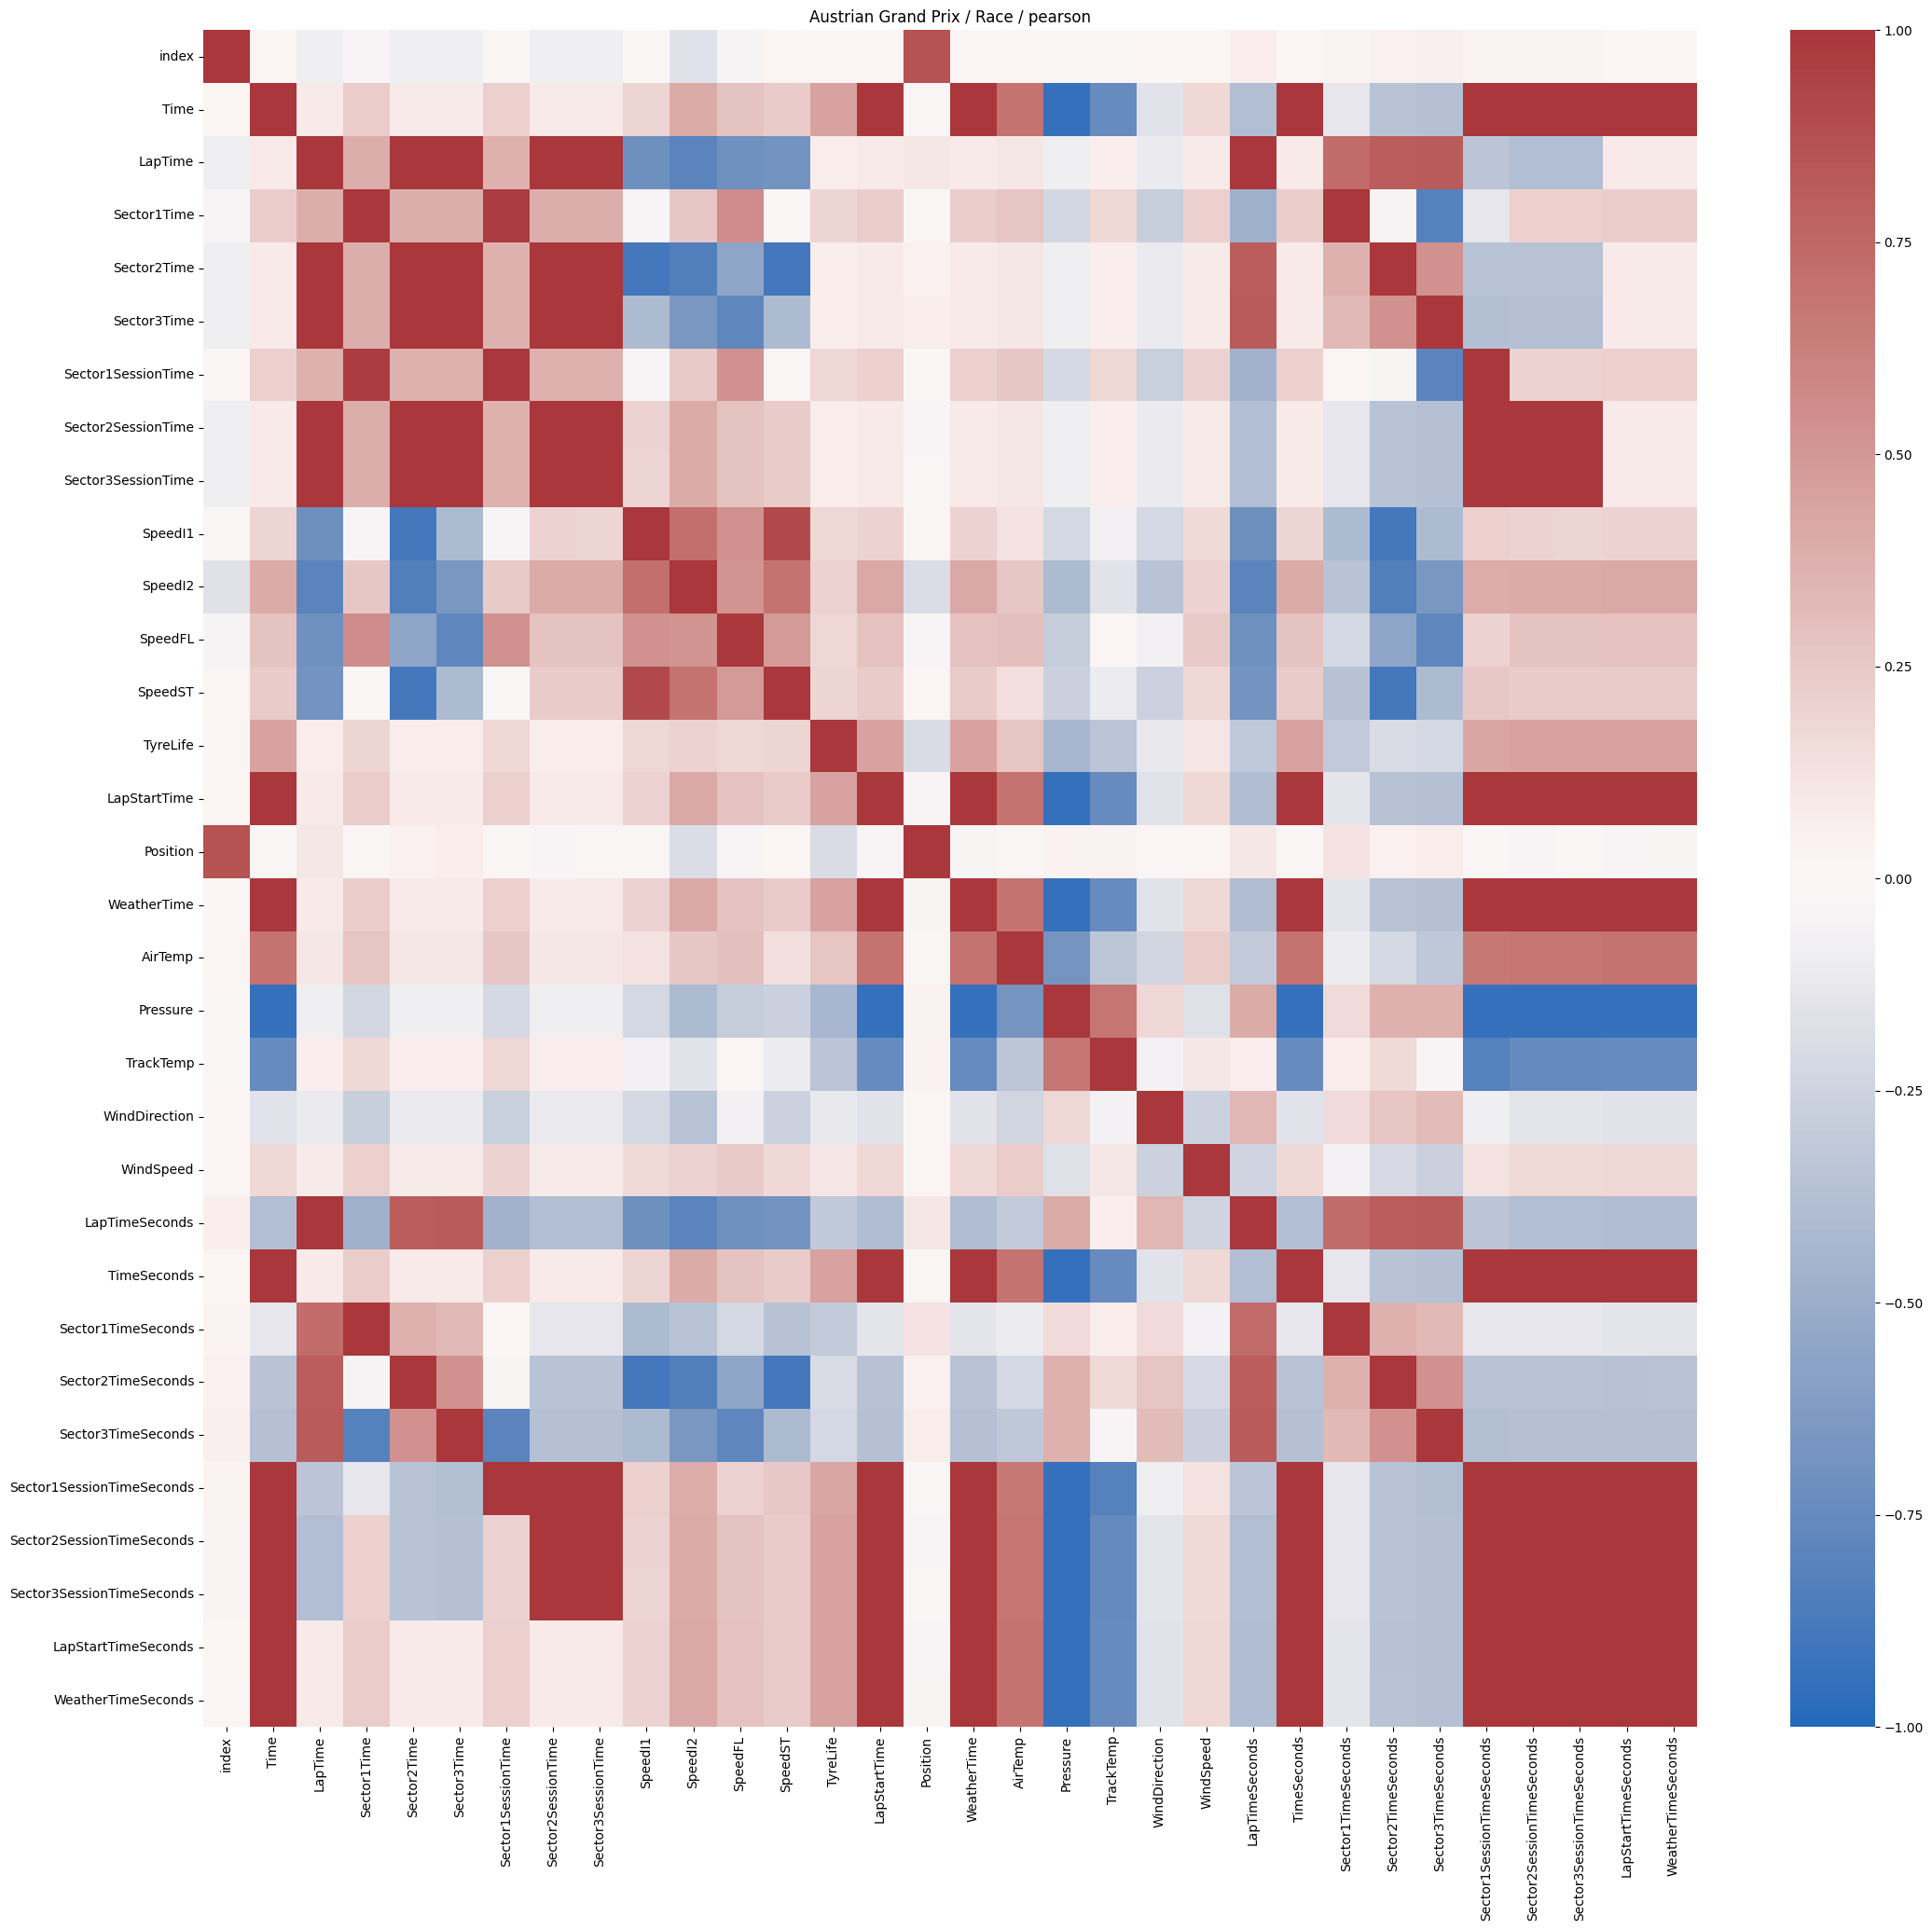

Austrian Grand Prix spearman uwzględnione pola: 32 = ['index', 'Time', 'LapTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'TyreLife', 'LapStartTime', 'Position', 'WeatherTime', 'AirTemp', 'Pressure', 'TrackTemp', 'WindDirection', 'WindSpeed', 'LapTimeSeconds', 'TimeSeconds', 'Sector1TimeSeconds', 'Sector2TimeSeconds', 'Sector3TimeSeconds', 'Sector1SessionTimeSeconds', 'Sector2SessionTimeSeconds', 'Sector3SessionTimeSeconds', 'LapStartTimeSeconds', 'WeatherTimeSeconds']


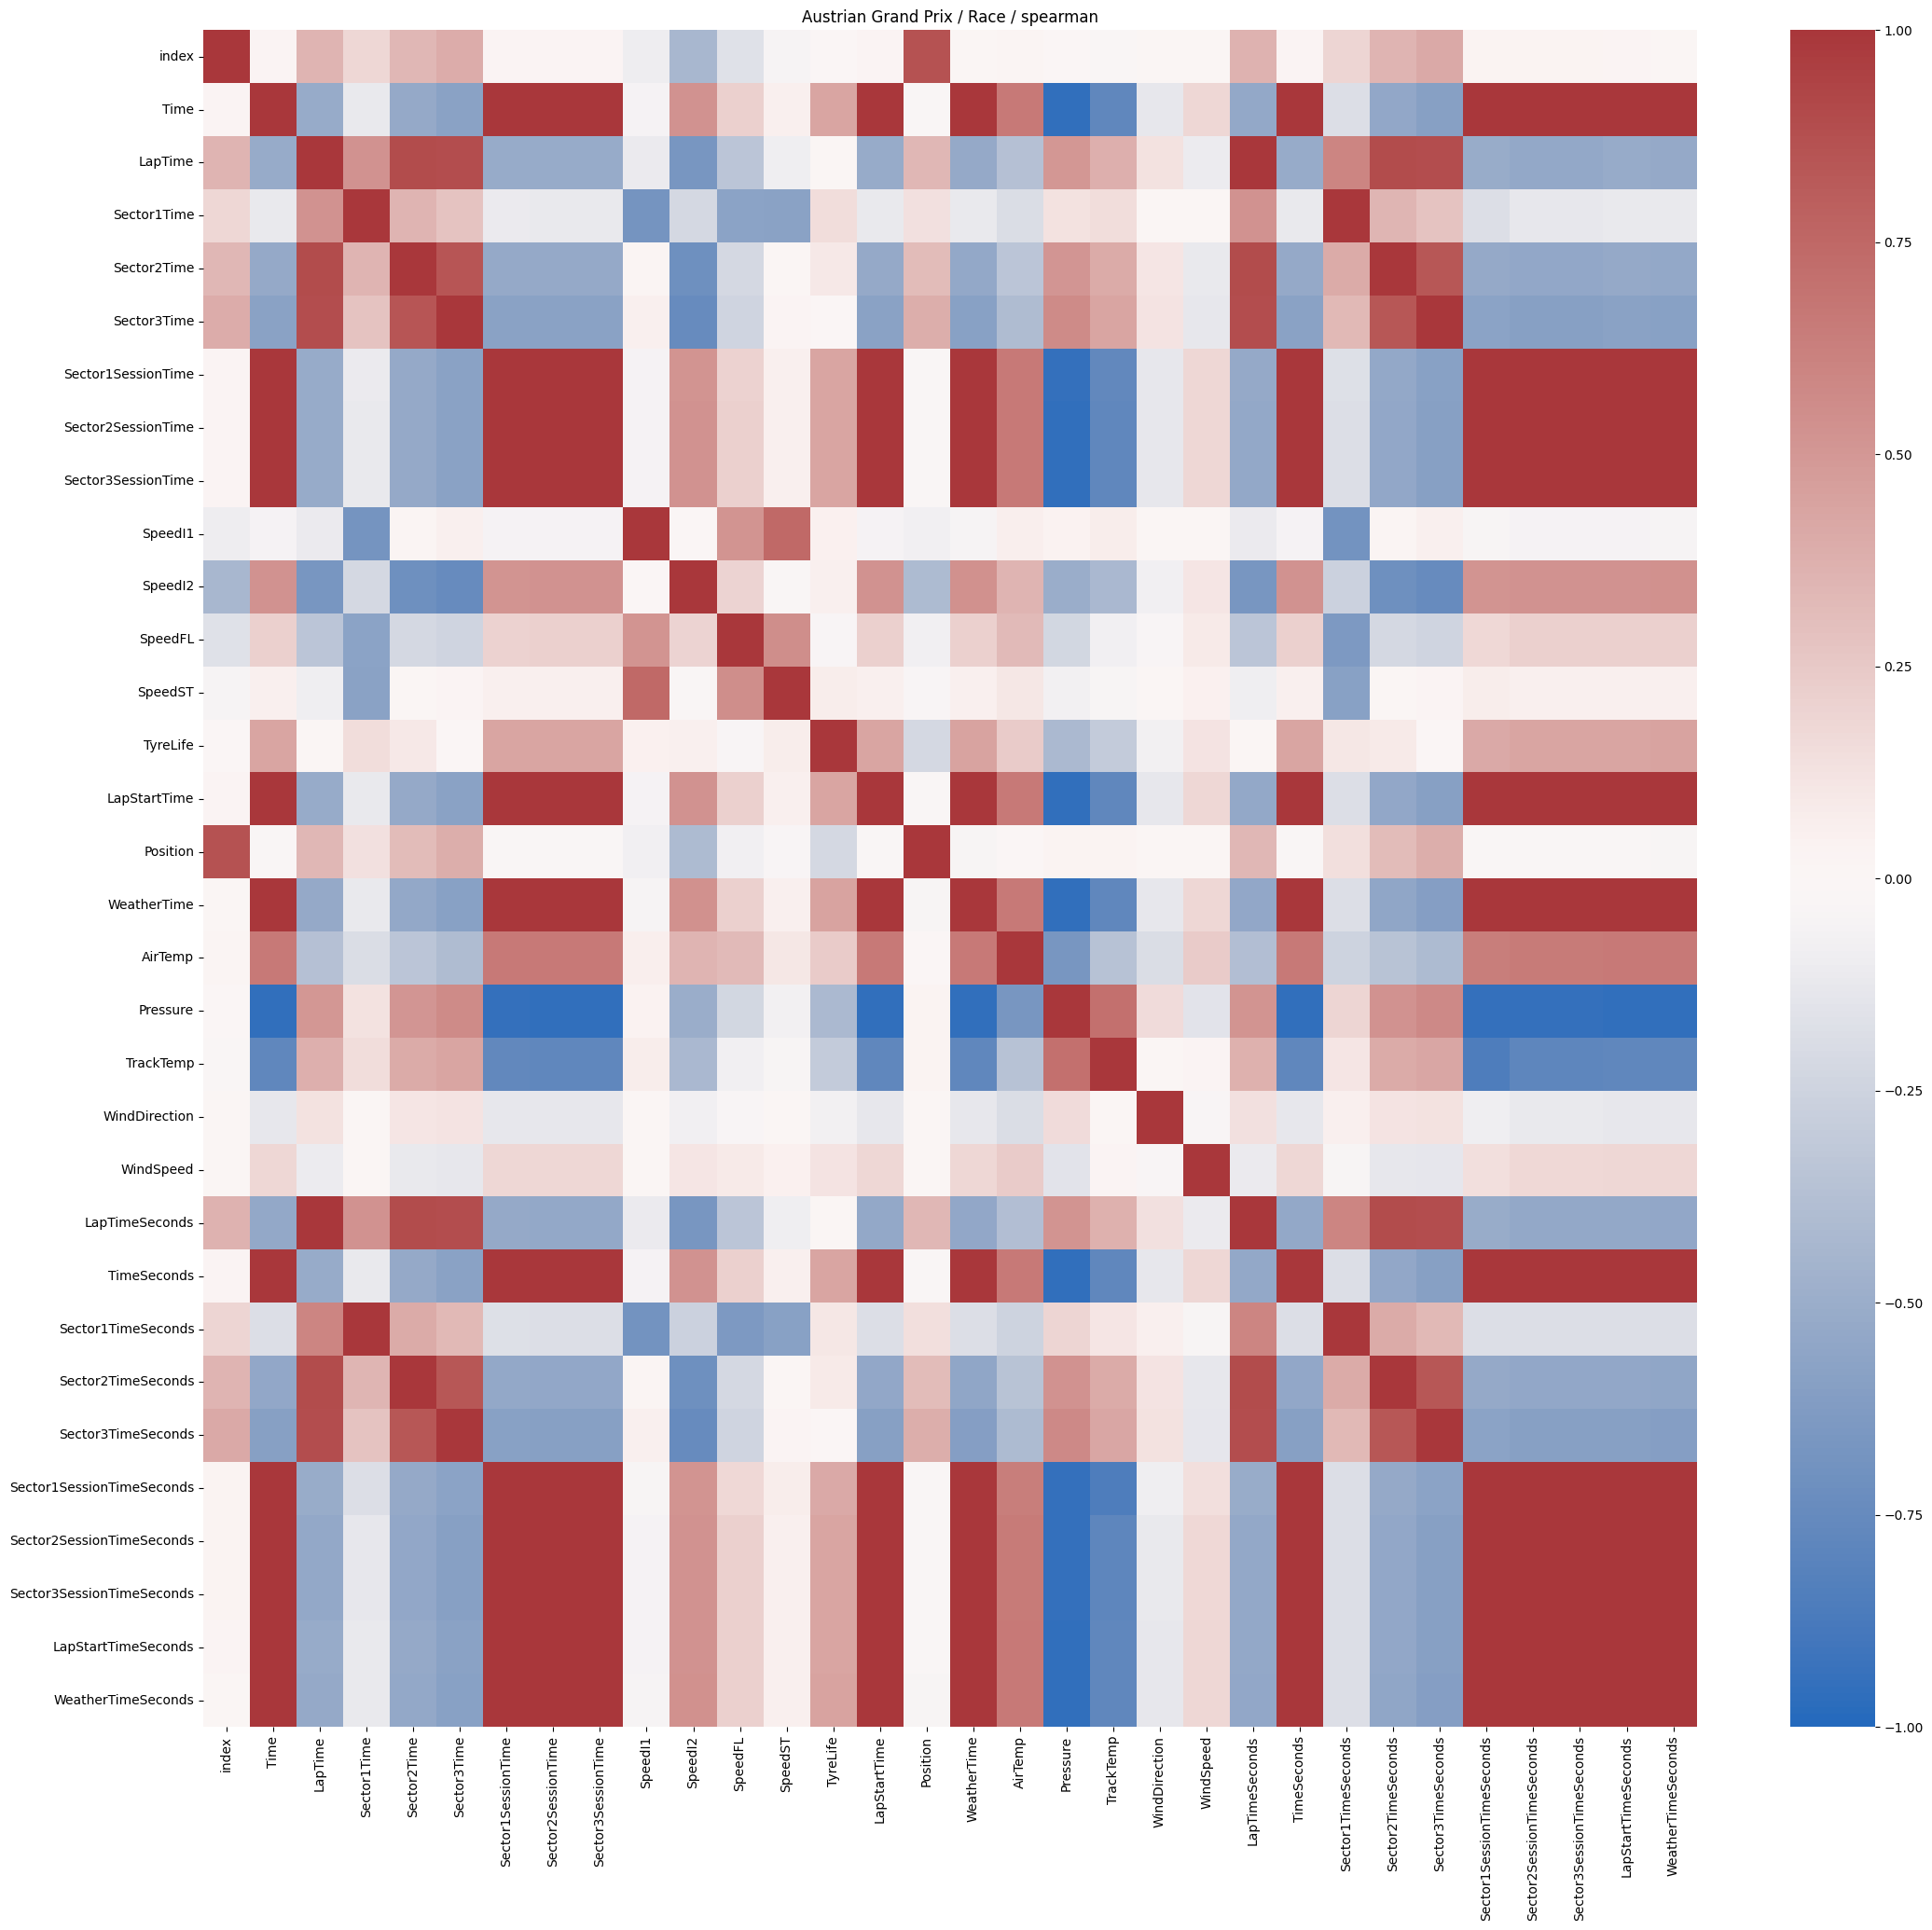

Azerbaijan Grand Prix pearson uwzględnione pola: 32 = ['index', 'Time', 'LapTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'TyreLife', 'LapStartTime', 'Position', 'WeatherTime', 'AirTemp', 'Pressure', 'TrackTemp', 'WindDirection', 'WindSpeed', 'LapTimeSeconds', 'TimeSeconds', 'Sector1TimeSeconds', 'Sector2TimeSeconds', 'Sector3TimeSeconds', 'Sector1SessionTimeSeconds', 'Sector2SessionTimeSeconds', 'Sector3SessionTimeSeconds', 'LapStartTimeSeconds', 'WeatherTimeSeconds']


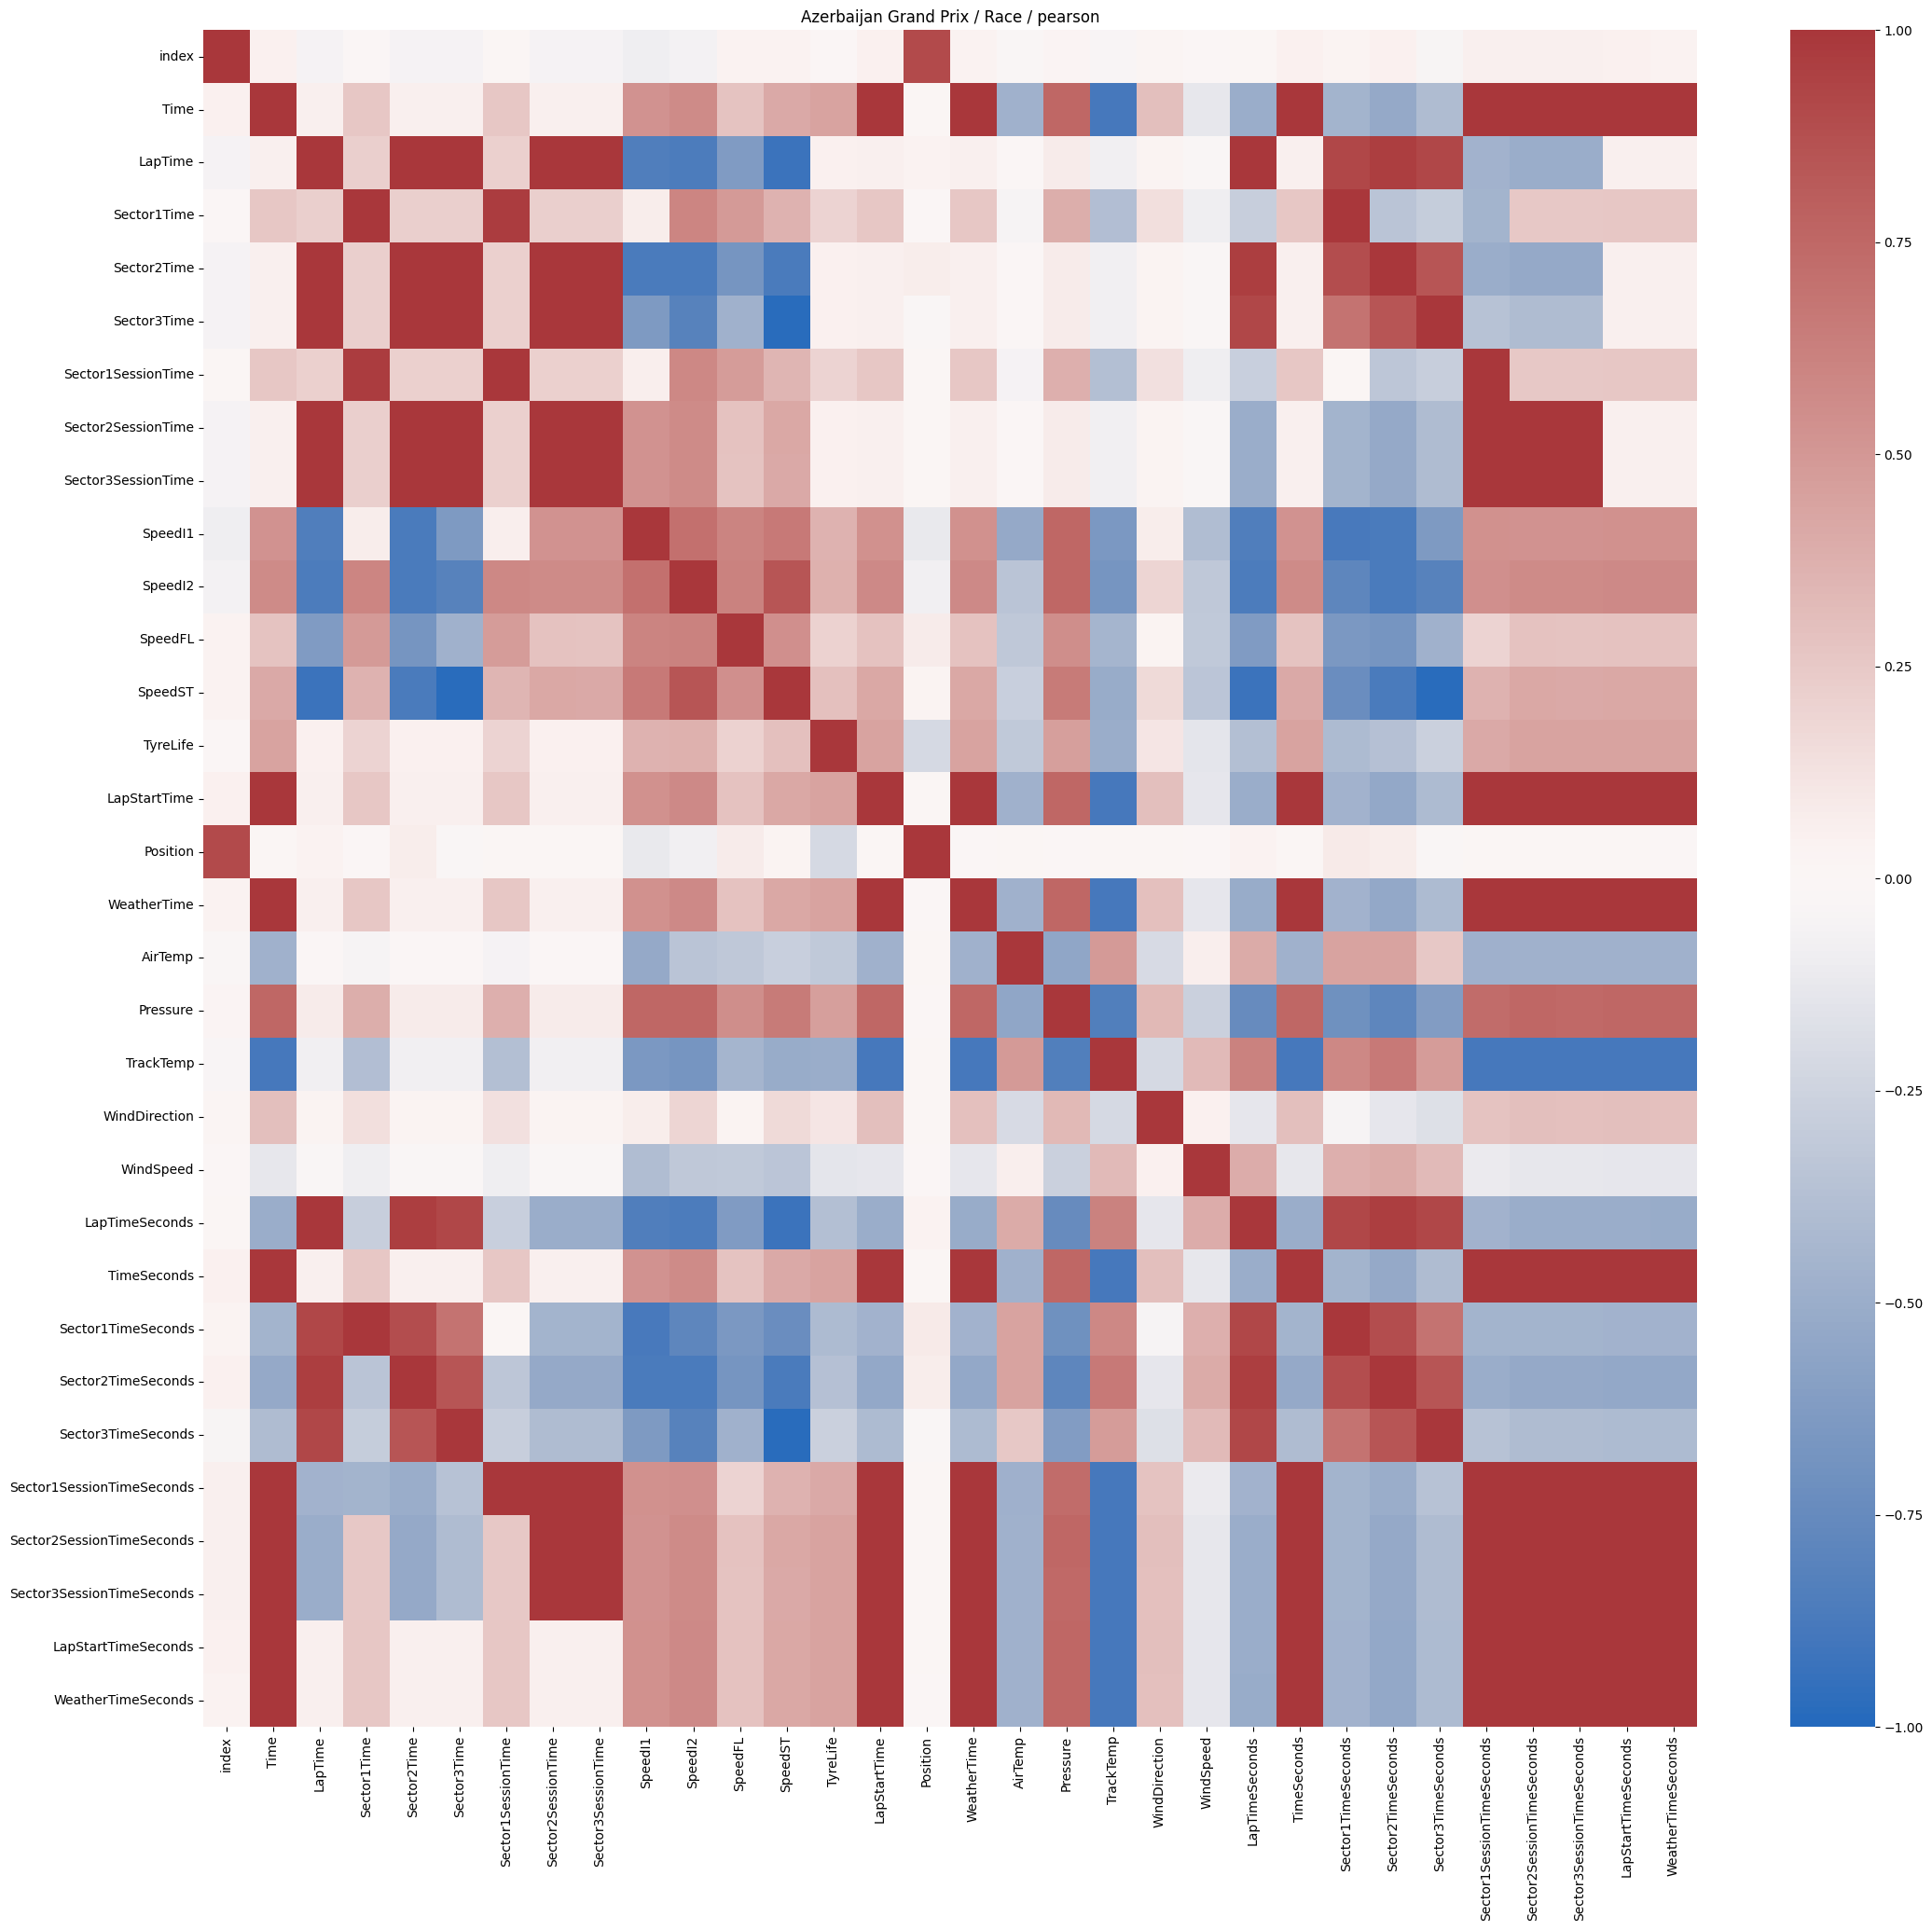

Azerbaijan Grand Prix spearman uwzględnione pola: 32 = ['index', 'Time', 'LapTime', 'Sector1Time', 'Sector2Time', 'Sector3Time', 'Sector1SessionTime', 'Sector2SessionTime', 'Sector3SessionTime', 'SpeedI1', 'SpeedI2', 'SpeedFL', 'SpeedST', 'TyreLife', 'LapStartTime', 'Position', 'WeatherTime', 'AirTemp', 'Pressure', 'TrackTemp', 'WindDirection', 'WindSpeed', 'LapTimeSeconds', 'TimeSeconds', 'Sector1TimeSeconds', 'Sector2TimeSeconds', 'Sector3TimeSeconds', 'Sector1SessionTimeSeconds', 'Sector2SessionTimeSeconds', 'Sector3SessionTimeSeconds', 'LapStartTimeSeconds', 'WeatherTimeSeconds']


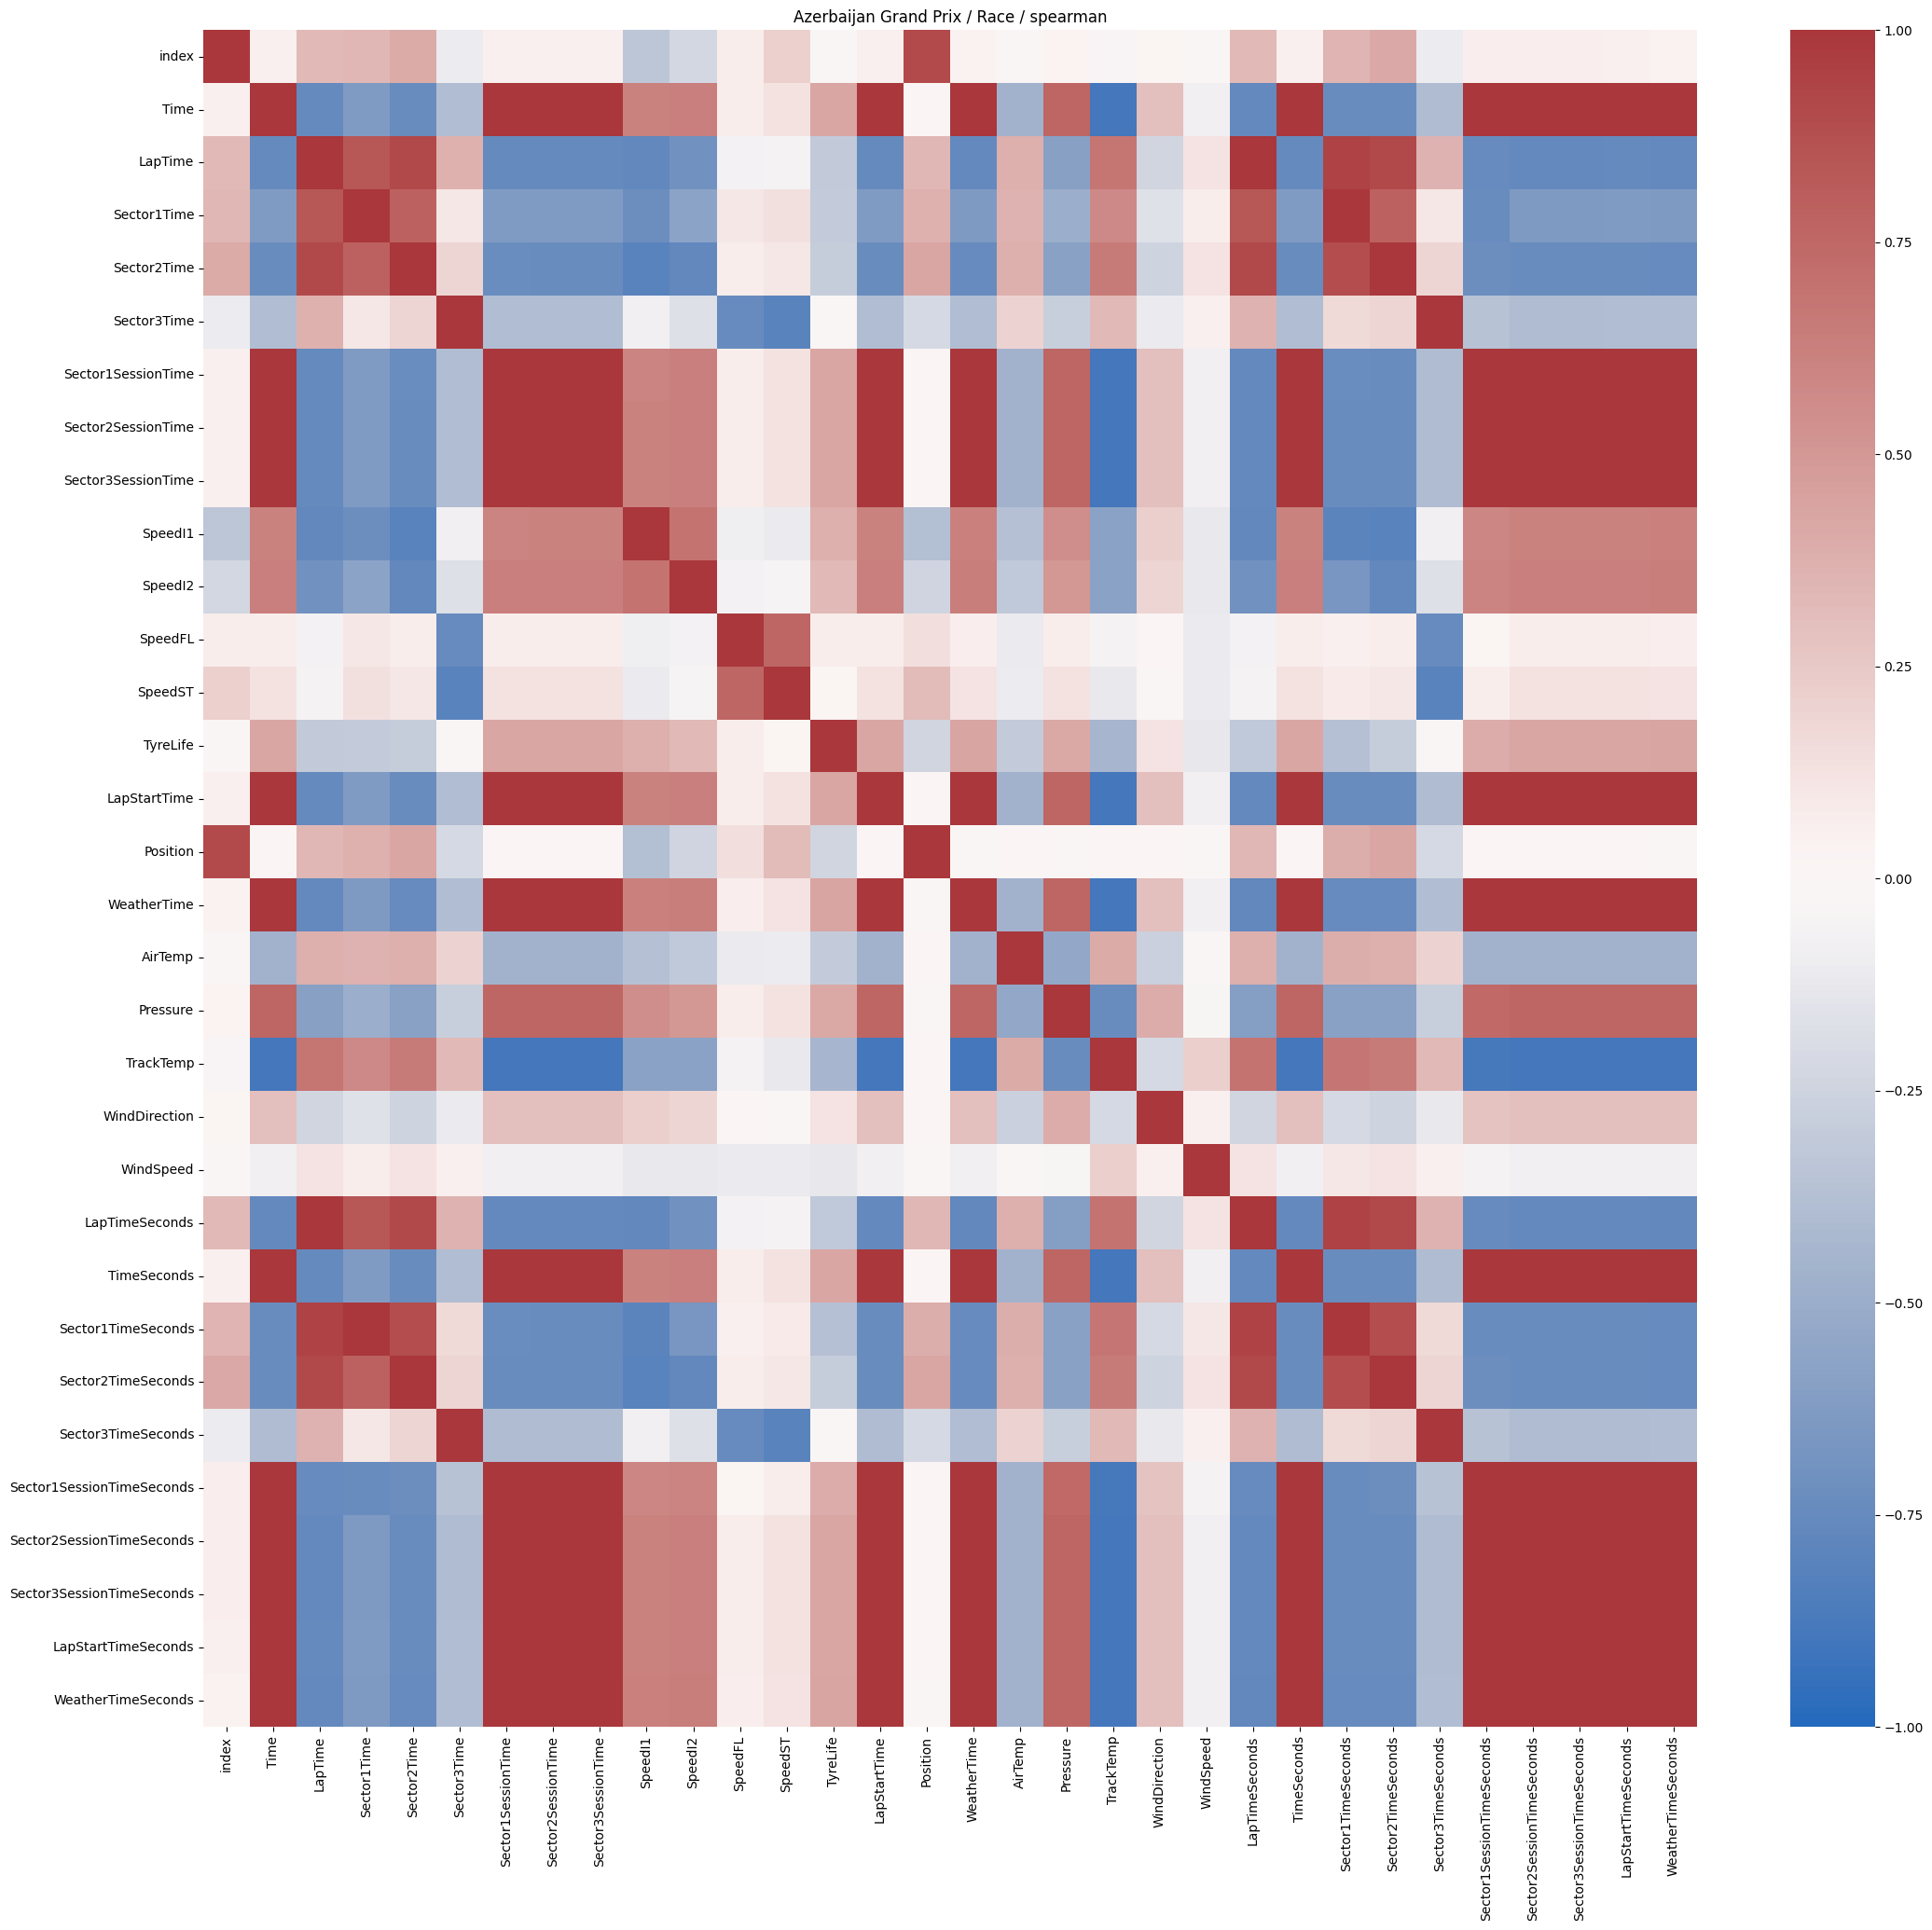

,event,method,param_a,param_b,r,abs_r,n_pair
62,Austrian Grand Prix,pearson,LapTime,Sector2Time,1.0,1.0,1124
606,Austrian Grand Prix,spearman,Sector1Time,Sector1TimeSeconds,1.0,1.0,1107
1540,Azerbaijan Grand Prix,spearman,Time,TimeSeconds,1.0,1.0,968
1846,Azerbaijan Grand Prix,spearman,LapStartTime,LapStartTimeSeconds,1.0,1.0,968
687,Austrian Grand Prix,spearman,Sector1SessionTime,Sector1SessionTimeSeconds,1.0,1.0,1106
661,Austrian Grand Prix,spearman,Sector3Time,Sector3TimeSeconds,1.0,1.0,1124
712,Austrian Grand Prix,spearman,Sector2SessionTime,Sector2SessionTimeSeconds,1.0,1.0,1124
1598,Azerbaijan Grand Prix,spearman,Sector1Time,Sector1TimeSeconds,1.0,1.0,948
548,Austrian Grand Prix,spearman,Time,TimeSeconds,1.0,1.0,1127
576,Austrian Grand Prix,spearman,LapTime,LapTimeSeconds,1.0,1.0,1124


In [9]:
EXCLUDE={'Year','LapNumber','Stint','DriverNumber'}
allowed=set(catalog.loc[~catalog.group.isin(['identyfikator/kontekst']),'column'])
def numerical_frame(df):
    x=df.select_dtypes(include='number').drop(columns=list(EXCLUDE & set(df.columns)),errors='ignore')
    x=x.loc[:,[c for c in x if c in allowed and x[c].notna().sum()>=max(10,int(.30*len(x))) and x[c].nunique(dropna=True)>1]]
    return x.replace([np.inf,-np.inf],np.nan)

def correlations(ev, method):
    g=laps[laps.Event==ev]
    x=numerical_frame(g)
    print(ev,method,'uwzględnione pola:',len(x.columns),'=',list(x.columns))
    corr=x.corr(method=method,min_periods=10)
    safe=ev.split()[0].lower()
    corr.to_csv(REPORTS/f'{safe}_{method}_matrix.csv')
    if corr.empty: return pd.DataFrame()
    plt.figure(figsize=(max(8,len(corr)*.7),max(6,len(corr)*.65)))
    sns.heatmap(corr,vmin=-1,vmax=1,cmap='vlag',center=0,annot=len(corr)<15,fmt='.2f')
    plt.title(f'{ev} / Race / {method}')
    plt.tight_layout();plt.savefig(REPORTS/f'{safe}_{method}_heatmap.png',dpi=170);plt.show()
    pairs=[]
    for i,a in enumerate(corr.columns):
        for b in corr.columns[i+1:]:
            n=int(x[[a,b]].dropna().shape[0]); r=corr.loc[a,b]
            if pd.notna(r):pairs.append({'event':ev,'method':method,'param_a':a,'param_b':b,'r':r,'abs_r':abs(r),'n_pair':n})
    return pd.DataFrame(pairs)

all_pairs=[]
for event in EVENTS:
    for method in ['pearson','spearman']:
        p=correlations(event,method)
        if not p.empty: all_pairs.append(p)
pairs=pd.concat(all_pairs,ignore_index=True) if all_pairs else pd.DataFrame()
if not pairs.empty:
    pairs=pairs.sort_values('abs_r',ascending=False)
    pairs.to_csv(REPORTS/'all_pair_correlations.csv',index=False)
    display(pairs.groupby(['event','method']).head(15))

7. Zmienne kategoryczne i binarne
Nie kodujemy identyfikatorów kierowców jako 1, 2, 3 i nie liczmy z nich korelacji Pearsona. Dla parametrów kategorycznych oglądamy grupowe rozkłady liczbowe, a dla dwóch kategorii stosujemy bezpieczne porównanie. Małe grupy pokazujemy jawnie.

Zmienna wyniku do wykresów grupowych: LapTimeSeconds ; kategorie: ['Compound', 'Driver', 'Team', 'TrackStatus']


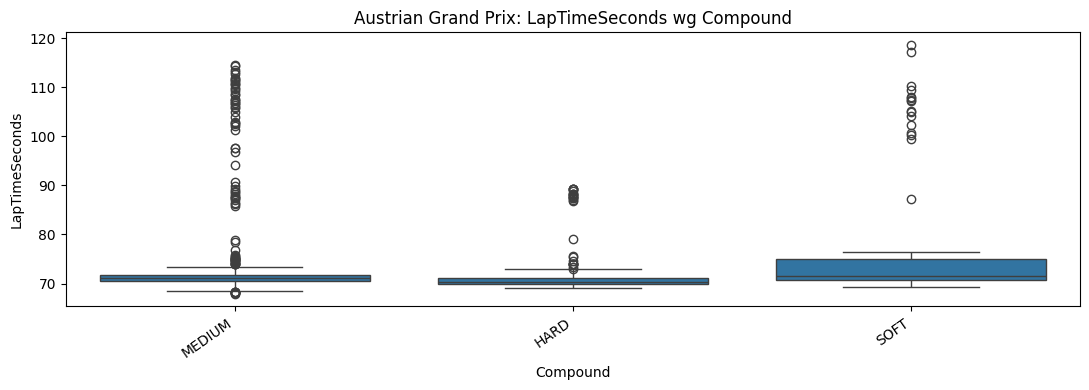

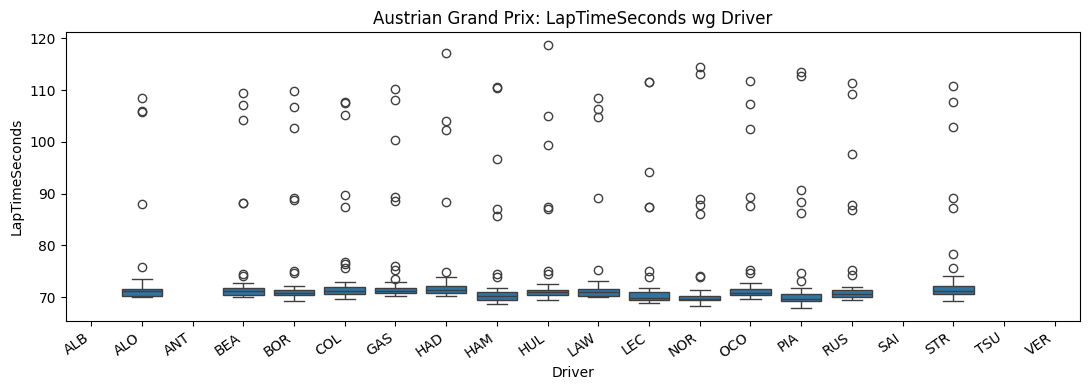

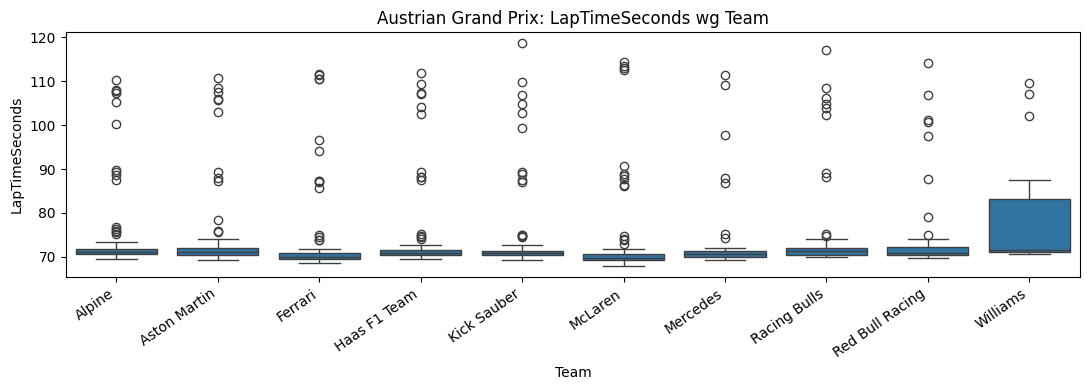

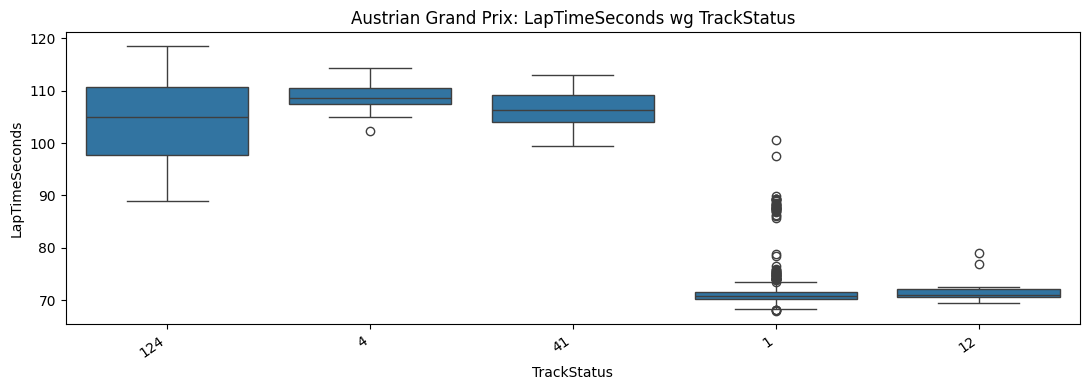

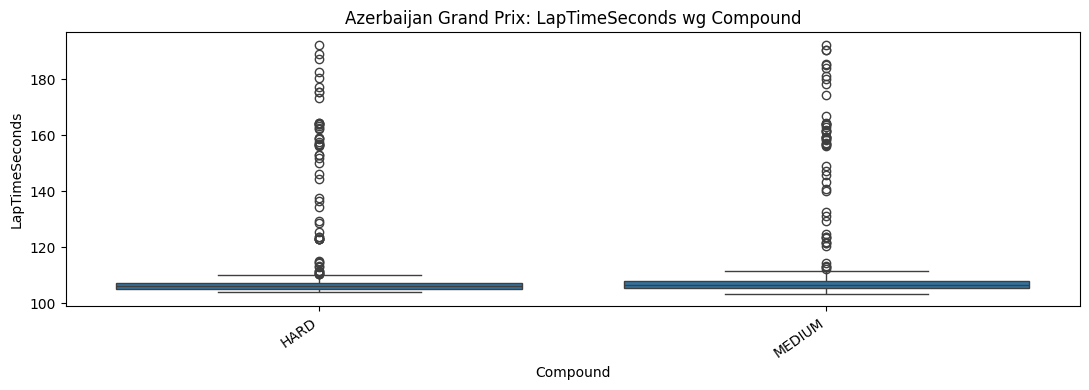

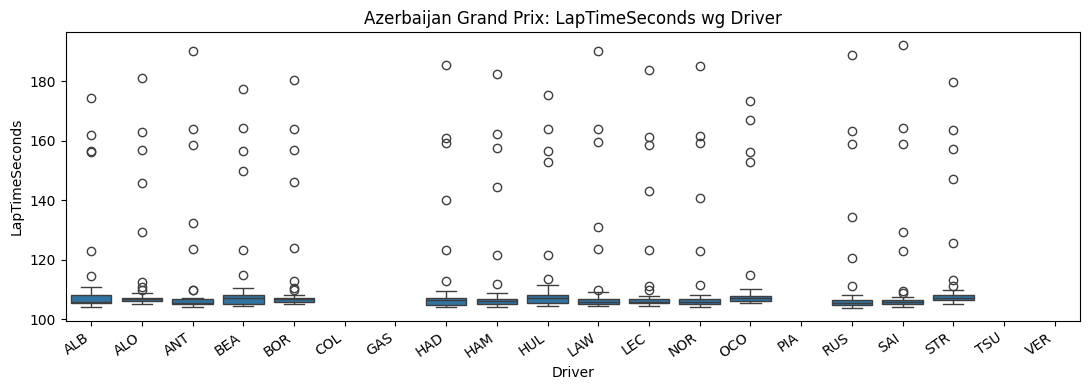

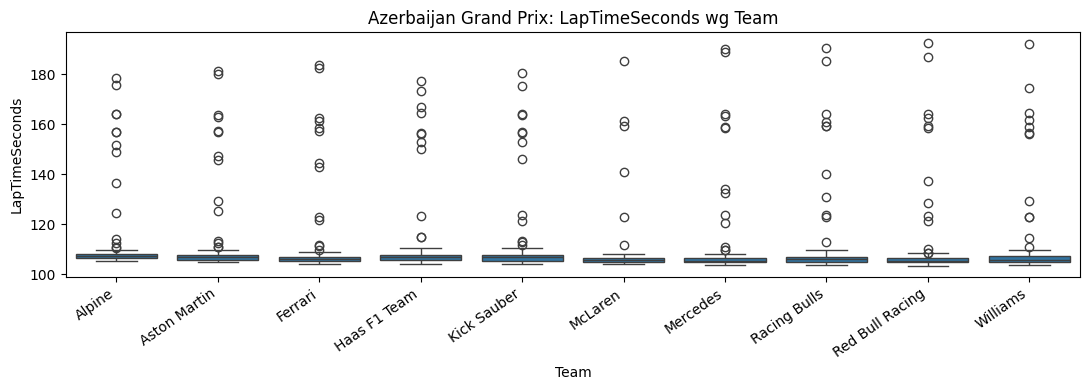

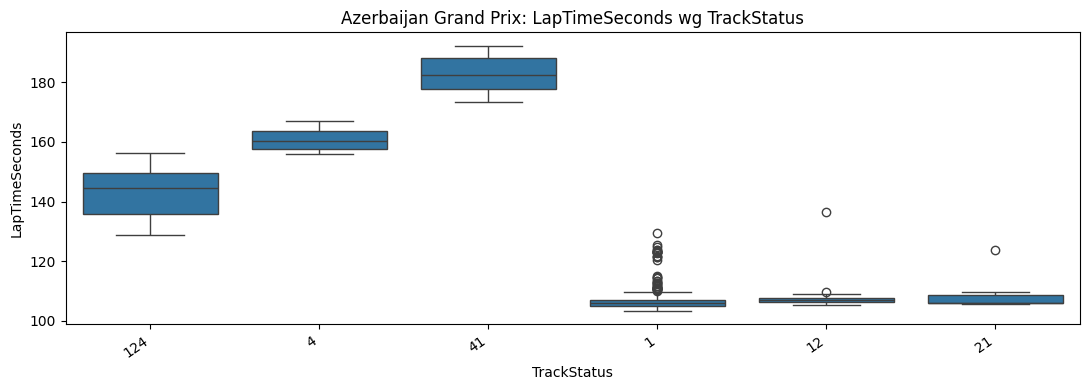

In [10]:
target=next((c for c in ['LapTimeSeconds','LapTime_Seconds','LapTime'] if c in laps and pd.api.types.is_numeric_dtype(laps[c])),None)
categories=[c for c in ['Compound','Driver','Team','TrackStatus'] if c in laps]
print('Zmienna wyniku do wykresów grupowych:',target,'; kategorie:',categories)
if target:
    for ev in EVENTS:
        g=laps[laps.Event==ev]
        for cat in categories:
            counts=g[cat].value_counts(dropna=True)
            popular=counts[counts>=5].index[:15]
            sub=g[g[cat].isin(popular)].copy()
            if sub.empty: continue
            plt.figure(figsize=(11,4))
            sns.boxplot(data=sub,x=cat,y=target)
            plt.xticks(rotation=35,ha='right');plt.title(f'{ev}: {target} wg {cat}')
            plt.tight_layout();plt.savefig(REPORTS/f'{ev.split()[0].lower()}_{cat}_boxplot.png',dpi=160);plt.show()
else:
    print('Brak liczbowej kolumny LapTimeSeconds — obejrzyj katalog i zdefiniuj kolumnę docelową.')

8. Porównanie torów
Sprawdzamy, czy ta sama para zmiennych ma podobny kierunek/siłę korelacji. Dla dwóch GP jest to ocena eksploracyjna, nie potwierdzenie ogólności zależności.

In [11]:
if not pairs.empty:
    wide=pairs.pivot_table(index=['method','param_a','param_b'],columns='event',values='r').dropna().reset_index()
    if len(wide):
        wide['difference_abs']=abs(wide[EVENTS[0]]-wide[EVENTS[1]])
        wide=wide.sort_values('difference_abs',ascending=False)
        display(wide.head(25));wide.to_csv(REPORTS/'austria_azerbaijan_comparison.csv',index=False)
    else: print('Brak wspólnych par korelacyjnych.')

event,method,param_a,param_b,Austrian Grand Prix,Azerbaijan Grand Prix,difference_abs
928,spearman,WeatherTime,Pressure,-0.953596,0.765534,1.719130
592,spearman,Pressure,WeatherTimeSeconds,-0.953596,0.765534,1.719130
514,spearman,LapStartTime,Pressure,-0.953475,0.765386,1.718861
582,spearman,Pressure,LapStartTimeSeconds,-0.953475,0.765386,1.718861
590,spearman,Pressure,TimeSeconds,-0.953448,0.765383,1.718830
863,spearman,Time,Pressure,-0.953448,0.765383,1.718830
724,spearman,Sector3SessionTime,Pressure,-0.953448,0.765383,1.718830
664,spearman,Sector2SessionTime,Pressure,-0.953445,0.765383,1.718827
588,spearman,Pressure,Sector3SessionTimeSeconds,-0.953117,0.764648,1.717765
586,spearman,Pressure,Sector2SessionTimeSeconds,-0.953113,0.764648,1.717761


9. Opcjonalnie: przebiegi funkcyjne telemetrii i agregaty z próbek
Próbki typu Speed(t), Throttle(t) i Brake(t) to funkcje, więc tworzymy m.in. średnią, maksimum, odchylenie, percentyle i udział próbek aktywnych. Udział próbek jest tylko przybliżeniem czasu, jeśli odstępy między próbkami nie są równe. Nie łączymy próbek z okrążeń w jedną niezależną próbę. Zostawiamy 10 okrążeń/GP na test; po weryfikacji możemy przetworzyć wszystkie. Funkcja get_driver / get_lap pochodzi z dokumentacji tif1.

In [13]:
def telemetry_features(t):
    out={}
    for key in ['Speed','RPM','Throttle','Brake','DRS','nGear','Ax','Ay','Az','Distance']:
        if key not in t: continue
        a=pd.to_numeric(t[key],errors='coerce').replace([np.inf,-np.inf],np.nan).dropna()
        if a.empty:continue
        out[f'{key}_mean']=a.mean()
        out[f'{key}_std']=a.std()
        out[f'{key}_p10']=a.quantile(.1)
        out[f'{key}_p90']=a.quantile(.9)
        if key in ['Brake','DRS']: out[f'{key}_nonzero_sample_share']=(a!=0).mean()
    return out

if FETCH_TELEMETRY:
    rows=[];errors=[]
    for ev in EVENTS:
        g=laps[laps.Event==ev]
        required={'Driver','LapNumber'}
        if not required.issubset(g.columns):
            print('Brak wymaganych kolumn:',required-set(g.columns));continue
        targets=g.dropna(subset=['Driver','LapNumber']).drop_duplicates(['Driver','LapNumber'])
        if MAX_TELEMETRY_LAPS_PER_GP is not None: targets=targets.head(MAX_TELEMETRY_LAPS_PER_GP)
        for _,lap in targets.iterrows():
            try:
                driver=sessions[ev].get_driver(str(lap['Driver']))
                telemetry=pd.DataFrame(driver.get_lap(int(lap['LapNumber'])).telemetry)
                rows.append({'Event':ev,'Driver':lap['Driver'],'LapNumber':lap['LapNumber'],**telemetry_features(telemetry)})
            except Exception as e:errors.append({'Event':ev,'Driver':lap['Driver'],'LapNumber':lap['LapNumber'],'error':str(e)})
    features=pd.DataFrame(rows)
    if not features.empty:
        features.to_parquet(PROCESSED/'telemetry_lap_features.parquet',index=False)
        merged=laps.merge(features,on=['Event','Driver','LapNumber'],how='left',validate='one_to_one')
        merged.to_parquet(PROCESSED/'race_laps_with_telemetry_features.parquet',index=False)
        display(features.head())
    pd.DataFrame(errors).to_csv(REPORTS/'telemetry_errors.csv',index=False)
    print('Wyniki telemetrii:',len(rows),'błędów:',len(errors))
else:
    print('Włącz FETCH_TELEMETRY=True, aby dodać cechy funkcyjne.')

Włącz FETCH_TELEMETRY=True, aby dodać cechy funkcyjne.
